# 03 · Baseline model

Before building a CNN we train a **simple, fast model** on a few hand-made numbers per waveform. Its score is the **target the CNN must beat**. If a CNN cannot beat it, the CNN is not worth its complexity.

| Part | What |
|---|---|
| 0 | Setup |
| 1 | How we score a model (and why not accuracy) |
| 2 | The input: 14 features per waveform |
| 3 | Three models, trained with the session folds |
| 4 | Where the mistakes are: confusion matrices |
| 5 | Which sessions go wrong |
| 6 | Check 1: what a random split would have told us |
| 7 | Check 2: does the model rely on amplitude? |
| 8 | Which features matter |
| 9 | Save the results |
| 10 | Summary: the target for the CNN |

Everything uses the folds from notebook 02: each model is trained 3 times, and every file is predicted by a model that never saw its session.

## 0. Setup

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import warnings; warnings.filterwarnings("ignore", category=UserWarning)

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.model_selection import StratifiedKFold

from ureca.dataset.loading import CLASSES, FS, TRIGGER, load_index, load_waveforms, fold_split
from ureca.dataset.torch_data import preprocess
from ureca.models.features import compute_features, AMPLITUDE, SHAPE
from ureca.evaluate import cv_predict, metrics, score, confusion
from ureca.config import ensure_dirs
from ureca.plotting import (set_style, strip, confusion_plot, legend_handles,
                            NAMES, COLORS, FOLD_COLORS, INK, INK2, GRID, SURFACE)

set_style()
files = load_index()
X = load_waveforms(files)
y = files["y"].values

167 waveforms: 167 from cache, 0 read from text


## 1. How we score a model

**Accuracy** (the share of files predicted correctly) is misleading here: 139 of 167 files (83%) are switching noise. A "model" that **always answers switching noise** gets 83% accuracy while being useless: it never finds a single partial discharge.

So we use scores that treat every class equally:

| Score | Meaning |
|---|---|
| **Recall of a class** | Of the files that truly are class X, what share did the model call X? (PD recall = "how many PDs did we catch") |
| **Balanced accuracy** | The average of the 4 recalls |
| **Macro-F1** (main score) | F1 combines recall with *precision* (when the model says X, how often is it right?). Macro = the average over the 4 classes, each class counting equally |

All three go from 0 to 1. Below, the "always switching noise" model is scored to show the difference.

In [2]:
always_sn = np.full_like(y, CLASSES.index("switching_noise"))
pd.Series(metrics(y, always_sn)).round(3).to_frame("always 'switching noise'")

,always 'switching noise'
macro_f1,0.227
balanced_acc,0.250
accuracy,0.832
recall_partial_discharge,0.000
recall_switching_noise,1.000
recall_transient_noise,0.000
recall_spark_lighter,0.000


**Explanation:** accuracy is 0.83, which looks good, but macro-F1 is only **0.23** and PD recall is **0**. Macro-F1 exposes the useless model, so it is our main score. We will also look at PD recall separately, because missing a real PD is the costliest mistake in practice.

## 2. The input: 14 features per waveform

A simple model cannot read 16,384 raw samples. Instead we describe each waveform with **14 numbers (features)**, the same kinds of measurements we looked at in the EDA. The code is in `src/ureca/models/features.py`.

| Group | Feature | Meaning |
|---|---|---|
| **Amplitude** (depends on signal size in volts) | `peak` | largest absolute value |
| | `rms` | average signal size (energy) |
| | `clipped` | share of samples at the ±1 V limit of the recorder |
| **Shape** (unchanged if the waveform is scaled up or down) | `crest` | peak ÷ rms: spiky (high) or steady (low)? |
| | `kurtosis` | how much of the signal is in a few extreme samples |
| | `centroid_MHz` | "centre of mass" of the frequency spectrum |
| | `band_a_b MHz` (6 features) | share of energy in each frequency band |
| | `energy_near_trigger` | share of energy from −1 to +2 µs around the trigger |
| | `energy_late` | share of energy later than +10 µs (long ringing) |

We keep the two groups separate on purpose. The EDA showed that amplitude partly reflects the **recorder settings** (trigger level, clipping), not the physics of the event. Part 7 tests how much the model depends on it.

In [3]:
F = compute_features(X)
print(f"feature table: {F.shape[0]} files x {F.shape[1]} features")
F.assign(label=files["label"].map(NAMES)).groupby("label").median().T.round(3)

feature table: 167 files x 14 features


label,Partial discharge,Spark lighter,Switching noise,Transient noise
peak,0.097,1.001,0.062,0.249
rms,0.002,0.077,0.008,0.026
clipped,0.000,0.001,0.000,0.000
crest,38.727,11.841,8.557,9.693
kurtosis,447.905,37.809,18.897,27.278
centroid_MHz,29.803,3.314,4.089,2.486
band_0_2MHz,0.044,0.639,0.009,0.938
band_2_5MHz,0.115,0.264,0.171,0.020
band_5_10MHz,0.070,0.023,0.007,0.016
band_10_20MHz,0.055,0.005,0.020,0.002


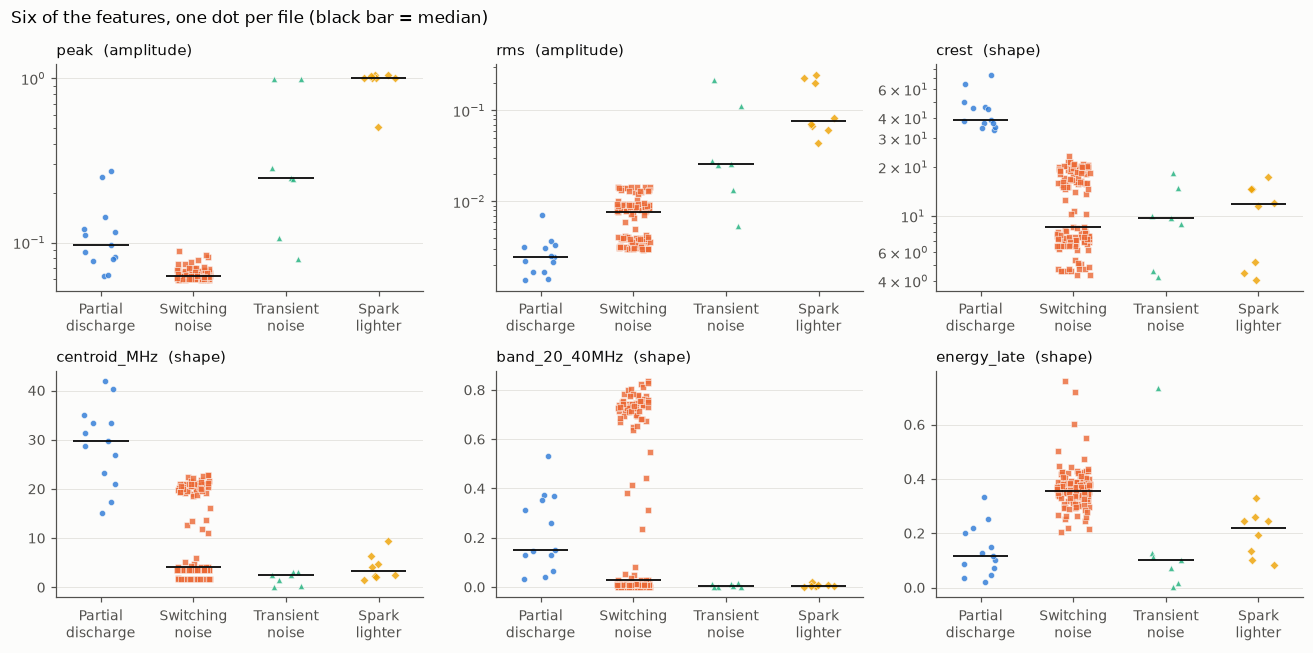

In [4]:
show = [("peak", True), ("rms", True), ("crest", True),
        ("centroid_MHz", False), ("band_20_40MHz", False), ("energy_late", False)]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, (col, log) in zip(axes.flat, show):
    strip(ax, F[col], files["label"], log=log)
    group = "amplitude" if col in AMPLITUDE else "shape"
    ax.set_title(f"{col}  ({group})", loc="left")
fig.suptitle("Six of the features, one dot per file (black bar = median)", x=0.01, ha="left")
plt.tight_layout(); plt.show()

**Explanation:**
- **Amplitude (top row):** the spark lighter is far larger than everything else, and PD is the smallest. That is very easy for a model to use, but it may be a recorder effect rather than physics.
- **Shape (bottom row):** PD has a high spectral centroid and a lot of energy at 20–40 MHz (fast, sharp pulses). Switching noise has a low centroid. These differences come from the physics of the event, so they should still hold with different recorder settings.
- The classes overlap in each single feature, but a model can combine all 14.

## 3. Three models, trained with the session folds

| Model | How it decides | Why include it |
|---|---|---|
| **Dummy** | always answers the most common class | the "zero-skill" floor; anything useful must beat it |
| **Logistic regression** | draws straight boundaries between classes in feature space | the simplest real model |
| **Random forest** | 300 small decision trees ("is centroid > 20 MHz? is peak < 0.1 V? ..."), which then vote | handles curved boundaries and features on very different scales |

Settings worth knowing:
- `class_weight="balanced"`: mistakes on rare classes cost more (the same idea as the class weights in notebook 02).
- Logistic regression first takes `log(1 + x)` and standardises each feature, because it needs features on similar scales; the forest does not.

`cv_predict` (in `src/ureca/evaluate.py`) trains a **fresh model for each fold** on the other two folds and predicts the held-out fold. At the end every file has exactly one *out-of-fold* prediction.

In [5]:
MODELS = {
    "Dummy": lambda: DummyClassifier(strategy="most_frequent"),
    "Logistic regression": lambda: make_pipeline(
        FunctionTransformer(np.log1p), StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=5000)),
    "Random forest": lambda: RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2, class_weight="balanced", random_state=0),
}
ALL = AMPLITUDE + SHAPE

preds, per_fold, overall = {}, {}, {}
for name, make in MODELS.items():
    preds[name] = cv_predict(make, F[ALL], files)
    per_fold[name], overall[name] = score(y, preds[name], files["fold"])

results = pd.DataFrame(overall).T
results.insert(1, "macro_f1 fold mean ± sd", [
    f"{per_fold[m]['macro_f1'].mean():.2f} ± {per_fold[m]['macro_f1'].std():.2f}" for m in MODELS])
results.round(3)

,macro_f1,macro_f1 fold mean ± sd,balanced_acc,accuracy,recall_partial_discharge,recall_switching_noise,recall_transient_noise,recall_spark_lighter
Dummy,0.227,0.22 ± 0.03,0.250,0.832,0.000,1.000,0.000,0.000
Logistic regression,0.533,0.59 ± 0.14,0.745,0.533,0.923,0.468,0.714,0.875
Random forest,0.763,0.72 ± 0.17,0.828,0.880,1.000,0.885,0.429,1.000


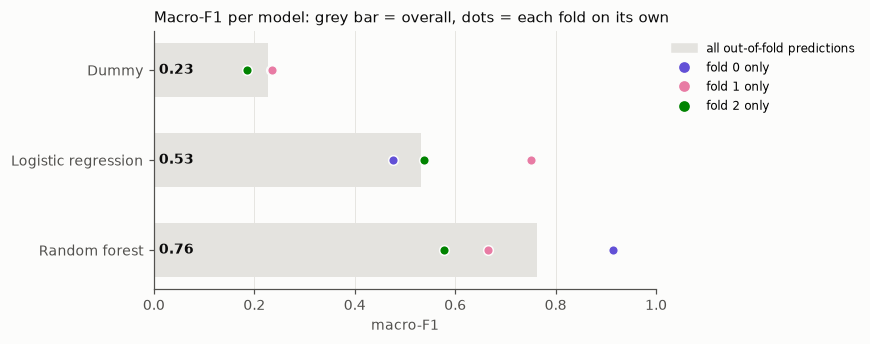

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for i, m in enumerate(MODELS):
    ax.barh(i, overall[m]["macro_f1"], color=GRID, height=0.6)
    ax.text(0.01, i, f"{overall[m]['macro_f1']:.2f}", va="center", color=INK, fontsize=9, fontweight="bold")
    for k, v in enumerate(per_fold[m]["macro_f1"]):
        ax.scatter(v, i, color=FOLD_COLORS[k], s=40, zorder=3, edgecolor=SURFACE)
ax.set_yticks(range(len(MODELS)), list(MODELS)); ax.invert_yaxis()
ax.set_xlim(0, 1); ax.set_xlabel("macro-F1"); ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=GRID, label="all out-of-fold predictions")] +
          [plt.Line2D([], [], color=FOLD_COLORS[k], marker="o", linestyle="", label=f"fold {k} only") for k in range(3)],
          loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
ax.set_title("Macro-F1 per model: grey bar = overall, dots = each fold on its own", loc="left")
plt.tight_layout(); plt.show()

**Explanation:**
- **Dummy ≈ 0.23**: the floor.
- **Logistic regression ≈ 0.53**: clearly better than the floor but weak. A straight boundary is not enough here.
- **Random forest ≈ 0.76**: the best baseline. **This is the number the CNN must beat.**
- The dots show the score **changes a lot between folds** (for the forest from about 0.58 to 0.92). With so few rare-class files per fold, one or two files move the score a lot. So we should only trust differences between models that are larger than this spread.

## 4. Where the mistakes are: confusion matrices

A **confusion matrix** counts, for every true class (row), what the model predicted (column). Correct answers are on the diagonal. The colour shows the share of that row, so rare classes are as visible as common ones.

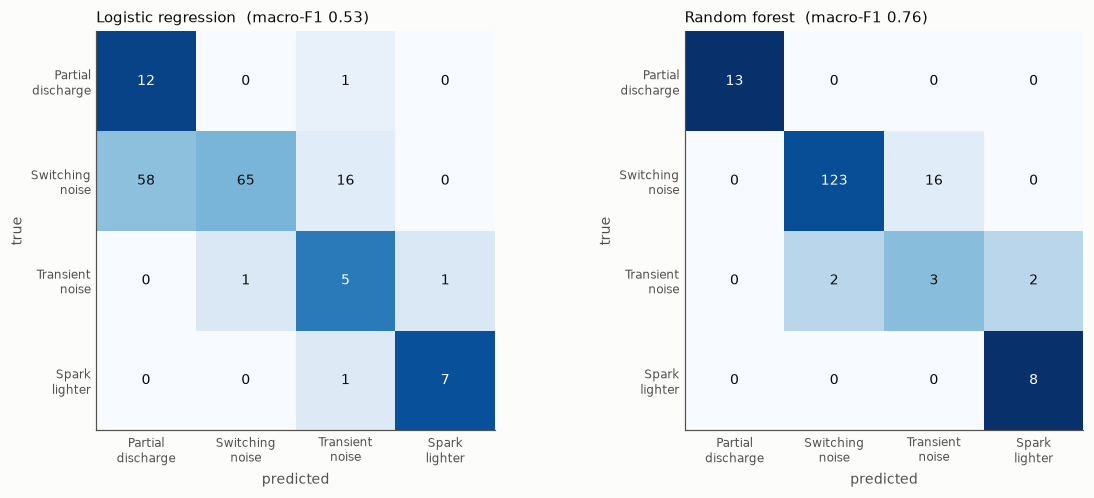

,Partial discharge,Switching noise,Transient noise,Spark lighter
Logistic regression,0.92,0.47,0.71,0.88
Random forest,1.00,0.88,0.43,1.00


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, m in zip(axes, ["Logistic regression", "Random forest"]):
    confusion_plot(ax, confusion(y, preds[m]), f"{m}  (macro-F1 {overall[m]['macro_f1']:.2f})")
plt.tight_layout(); plt.show()

recall = results[[f"recall_{c}" for c in CLASSES]].drop(index="Dummy")
recall.columns = [NAMES[c] for c in CLASSES]
recall.round(2)

**Explanation:**
- **Partial discharge:** the forest catches **all 13 PD files** and logistic regression catches 12 of 13. Good news: PD is the class that matters most.
- **Switching noise:** logistic regression calls **58 switching-noise files PD**, which would be a flood of false alarms. The forest does much better, but still calls 16 of them transient noise. These are not random mistakes; they come from whole sessions (part 5).
- **Transient noise** is the hardest class: with only 7 files from 5 sessions, each fold sees only 4–5 training examples.
- **Spark lighter** is easy for both, mostly because it is so loud (part 7 checks this).

## 5. Which sessions go wrong

Because files from one session are near-copies, mistakes come in **groups**. Here is the share of each session predicted correctly by the random forest.

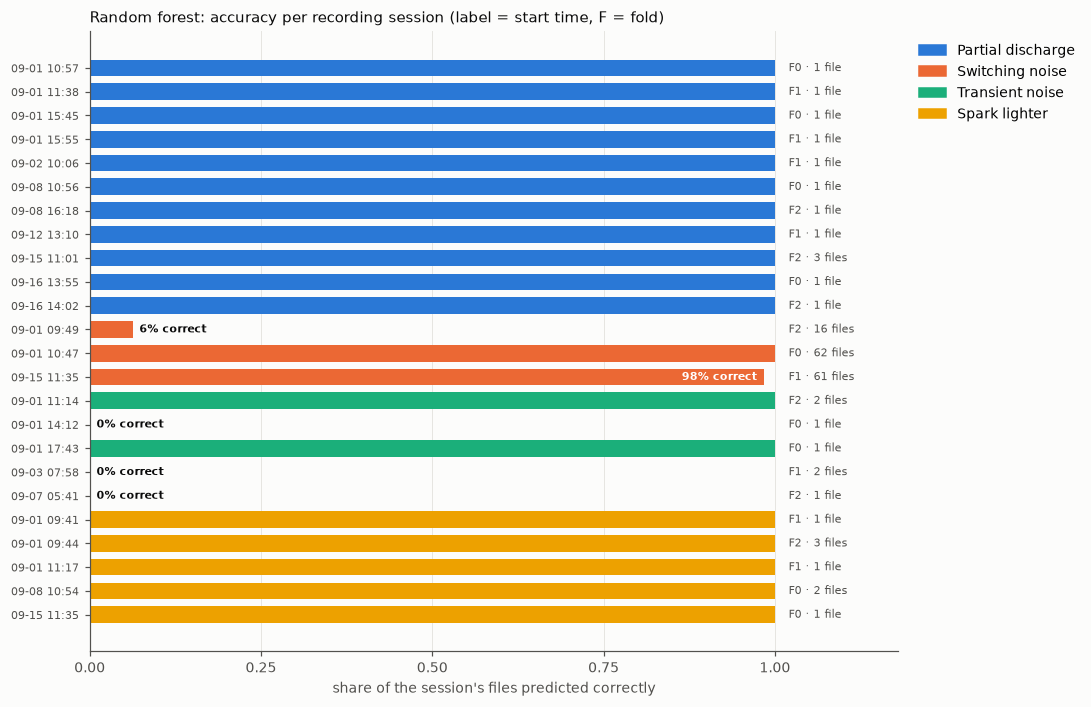

,label,fold,n,correct,predicted_as
session_id,,,,,
switching_noise@2026-09-01T09:49:24,switching_noise,2,16,0.06,"Transient noise ×15, Switching noise ×1"
switching_noise@2026-09-15T11:35:17,switching_noise,1,61,0.98,"Switching noise ×60, Transient noise ×1"
transient_noise@2026-09-01T14:12:59,transient_noise,0,1,0.00,Switching noise ×1
transient_noise@2026-09-03T07:58:38,transient_noise,1,2,0.00,Spark lighter ×2
transient_noise@2026-09-07T05:41:26,transient_noise,2,1,0.00,Switching noise ×1


In [8]:
pred_rf = preds["Random forest"]
files["pred_rf"] = [CLASSES[p] for p in pred_rf]
files["correct_rf"] = pred_rf == y
sess = (files.groupby("session_id")
        .agg(label=("label", "first"), fold=("fold", "first"), n=("file_id", "size"),
             correct=("correct_rf", "mean"),
             predicted_as=("pred_rf", lambda s: ", ".join(f"{NAMES[c]} ×{n}" for c, n in s.value_counts().items())))
        .sort_values(["label", "session_id"], key=lambda c: c.map(CLASSES.index) if c.name == "label" else c))

fig, ax = plt.subplots(figsize=(10, 6.5))
ypos = np.arange(len(sess))
ax.barh(ypos, sess["correct"], color=[COLORS[c] for c in sess["label"]], height=0.7)
for yi, (_, s) in zip(ypos, sess.iterrows()):
    ax.text(1.02, yi, f"F{s.fold} · {s.n} file{'s' if s.n > 1 else ''}", va="center", fontsize=7.5, color=INK2)
    if s.correct < 0.5:
        ax.text(s.correct + 0.01, yi, f"{s.correct:.0%} correct", va="center", fontsize=7.5, color=INK, fontweight="bold")
    elif s.correct < 1:
        ax.text(s.correct - 0.01, yi, f"{s.correct:.0%} correct", va="center", ha="right", fontsize=7.5, color="white", fontweight="bold")
ax.set_yticks(ypos, [s.split("@")[1].replace("T", " ")[5:16] for s in sess.index], fontsize=7.5)
ax.invert_yaxis(); ax.set_xlim(0, 1.18); ax.set_xticks([0, 0.25, 0.5, 0.75, 1]); ax.grid(axis="y", visible=False)
ax.set_xlabel("share of the session's files predicted correctly")
ax.legend(handles=[Patch(color=COLORS[c], label=NAMES[c]) for c in CLASSES], loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("Random forest: accuracy per recording session (label = start time, F = fold)", loc="left")
plt.tight_layout(); plt.show()

sess[sess["correct"] < 1][["label", "fold", "n", "correct", "predicted_as"]].round(2)

**Explanation:**
- Almost every session is either **fully right or largely wrong**. The model either recognises a session's "style" or it does not.
- The biggest single source of error is the **switching-noise session of 1 Sep 09:49** (fold 2): 15 of its 16 files are called transient noise. When fold 2 is held out, the model learns switching noise from only the two other sessions, and this one looks very different from them (see the waveforms below).
- **4 of the 7 transient-noise files** are missed (from 3 sessions). Each fold trains on only 4–5 transient-noise files, which is simply too few to learn the class.
- PD and spark lighter: every session is fully correct.

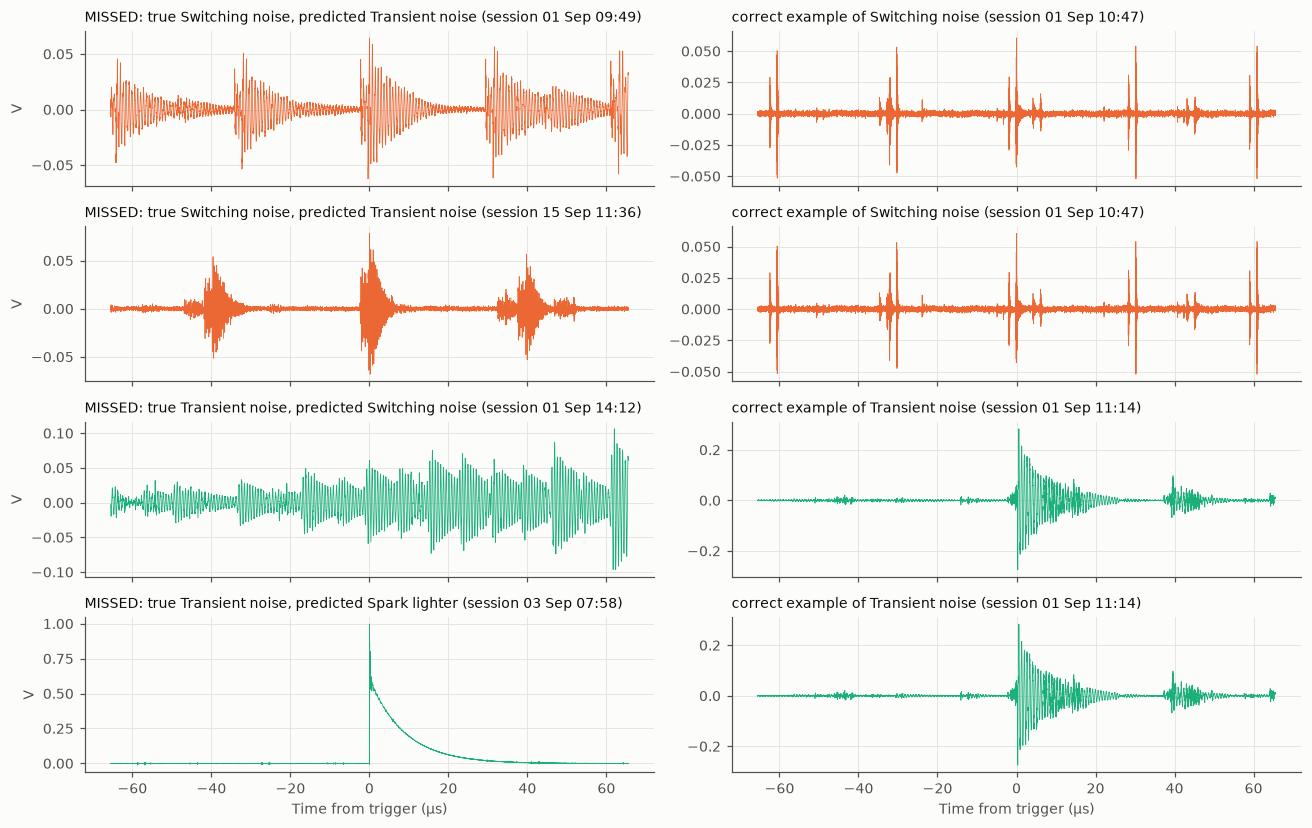

In [9]:
wrong = files[~files["correct_rf"]].groupby("session_id").head(1).head(4)
fig, axes = plt.subplots(len(wrong), 2, figsize=(12, 1.9 * len(wrong)), sharex=True)
axes = np.atleast_2d(axes)
t = (np.arange(X.shape[1]) - TRIGGER) / FS * 1e6
for r, (i, row) in enumerate(wrong.iterrows()):
    true, guess = row["label"], row["pred_rf"]
    # a correct file from the largest other session of the same class
    ok = files[(files["label"] == true) & files["correct_rf"] & (files["session_id"] != row["session_id"])]
    same = ok.index[ok["session_id"] == ok["session_id"].value_counts().index[0]] if len(ok) else []
    ax = axes[r, 0]
    ax.plot(t, X[i] - np.median(X[i]), color=COLORS[true], linewidth=0.5)
    ax.set_title(f"MISSED: true {NAMES[true]}, predicted {NAMES[guess]} (session {row['ts']:%d %b %H:%M})", loc="left", fontsize=9)
    ax = axes[r, 1]
    if len(same):
        j = same[0]
        ax.plot(t, X[j] - np.median(X[j]), color=COLORS[true], linewidth=0.5)
        ax.set_title(f"correct example of {NAMES[true]} (session {files.at[j, 'ts']:%d %b %H:%M})", loc="left", fontsize=9)
for ax in axes[-1]: ax.set_xlabel("Time from trigger (µs)")
for ax in axes[:, 0]: ax.set_ylabel("V")
plt.tight_layout(); plt.show()

**Explanation:** each row puts a missed file (left) next to a correctly classified file of the **same** class from another session (right).
- **Row 1:** switching noise from 1 Sep 09:49 is long bursts of ringing. The switching noise the model trained on (1 Sep 10:47) is short, sharp spikes. Same class, very different look. The model never saw this style, so it guesses transient noise.
- **Rows 3 and 4:** one transient-noise file is continuous ringing (similar to switching noise), and another is a single clipped spike with a smooth decay, much like a spark lighter.
- **Lesson:** the variety **within** each noise class is larger than our few sessions cover. This is mainly a **data** problem: a CNN may handle shapes a little better, but only recordings from more sessions will really fix it.

## 6. Check 1: what a random split would have told us

In notebook 02 we chose to split **by session** to avoid leakage. How much does it matter? We repeat the experiment with an ordinary **random** 3-fold split (files shuffled, sessions ignored), 5 times with different shuffles.

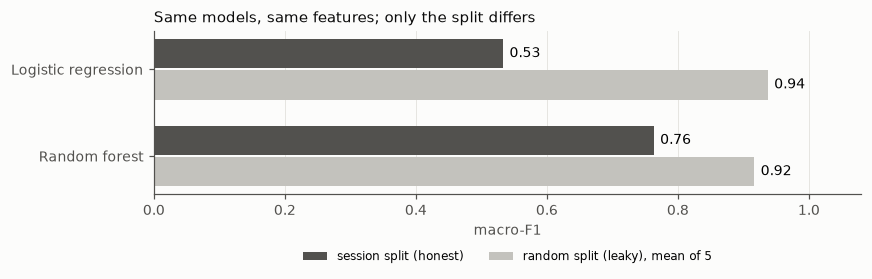

,session split (honest),"random split (leaky), mean of 5"
Logistic regression,0.533,0.937
Random forest,0.763,0.916


In [10]:
def random_split_f1(make, seed):
    pred = np.empty_like(y)
    for tr, va in StratifiedKFold(3, shuffle=True, random_state=seed).split(F, y):
        pred[va] = make().fit(F[ALL].values[tr], y[tr]).predict(F[ALL].values[va])
    return metrics(y, pred)["macro_f1"]

leak = pd.DataFrame({
    m: {"session split (honest)": overall[m]["macro_f1"],
        "random split (leaky), mean of 5": np.mean([random_split_f1(MODELS[m], s) for s in range(5)])}
    for m in ["Logistic regression", "Random forest"]}).T

fig, ax = plt.subplots(figsize=(8, 2.8))
for j, col in enumerate(leak.columns):
    ax.barh(np.arange(len(leak)) + (j - 0.5) * 0.36, leak[col], height=0.34,
            color=[INK2, "#c3c2bd"][j], label=col)
    for i, v in enumerate(leak[col]):
        ax.text(v + 0.01, i + (j - 0.5) * 0.36, f"{v:.2f}", va="center", fontsize=9)
ax.set_yticks(range(len(leak)), leak.index); ax.invert_yaxis()
ax.set_xlim(0, 1.08); ax.set_xlabel("macro-F1"); ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=2, fontsize=8)
ax.set_title("Same models, same features; only the split differs", loc="left")
plt.tight_layout(); plt.show()
leak.round(3)

**Explanation:** with a random split the random forest seems to reach **≈ 0.92**, and logistic regression jumps even more. The models did not get better: the random split puts near-copies of the same session in both training and validation, so the test becomes partly a memory test.

**Lesson:** always report the session-split score. If you read "95%" in a PD paper, check how they split the data.

## 7. Check 2: does the model rely on amplitude?

We train again using **only the 11 shape features** (no `peak`, `rms`, `clipped`). If the score stays similar, the model has learnt the physics. If it drops, it was leaning on signal size, which partly reflects recorder settings.

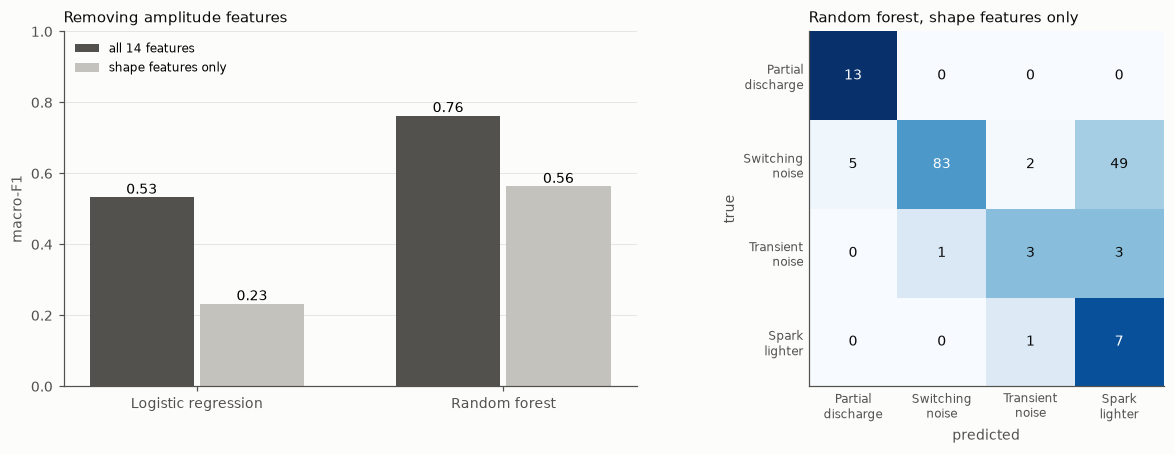

,all 14 features,shape features only
Logistic regression,0.533,0.233
Random forest,0.763,0.563


In [11]:
shape_only = {}
for m in ["Logistic regression", "Random forest"]:
    p = cv_predict(MODELS[m], F[SHAPE], files)
    shape_only[m] = metrics(y, p)
    if m == "Random forest":
        pred_rf_shape = p

cmp = pd.DataFrame({
    "all 14 features": {m: overall[m]["macro_f1"] for m in shape_only},
    "shape features only": {m: shape_only[m]["macro_f1"] for m in shape_only}})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.1]})
ax = axes[0]
for j, col in enumerate(cmp.columns):
    ax.bar(np.arange(len(cmp)) + (j - 0.5) * 0.36, cmp[col], width=0.34, color=[INK2, "#c3c2bd"][j], label=col)
    for i, v in enumerate(cmp[col]):
        ax.text(i + (j - 0.5) * 0.36, v + 0.01, f"{v:.2f}", ha="center", fontsize=9)
ax.set_xticks(range(len(cmp)), cmp.index); ax.set_ylim(0, 1); ax.set_ylabel("macro-F1")
ax.grid(axis="x", visible=False); ax.legend(loc="upper left", fontsize=8)
ax.set_title("Removing amplitude features", loc="left")
confusion_plot(axes[1], confusion(y, pred_rf_shape), "Random forest, shape features only")
plt.tight_layout(); plt.show()
cmp.round(3)

**Explanation:**
- Without amplitude, the random forest drops from **≈ 0.76 to ≈ 0.56**, and logistic regression falls to the dummy level. The baseline **depends heavily on signal size**.
- PD recall stays at 13 of 13, so PD's **shape** really is distinctive (its fast, high-frequency pulse).
- The noise classes suffer: **49 switching-noise files are now called spark lighter**. Without the volts, the model can no longer use "the spark lighter is loud", and our 11 shape numbers do not separate these two classes well.
- **Why this matters for the CNN:** a CNN sees the full waveform, so it can learn shape details that 11 summary numbers miss. A good test for the CNN is to train it on **peak-normalised** input (notebook 02, part 5). If it beats ≈ 0.56 by a lot, it has learnt real shape information that the baseline could not.

## 8. Which features matter

A random forest can report how much each feature helped its trees split the data (*impurity importance*). We average it over the 3 fold models. It is a rough guide only: with this little data, the ranking can shift between folds.

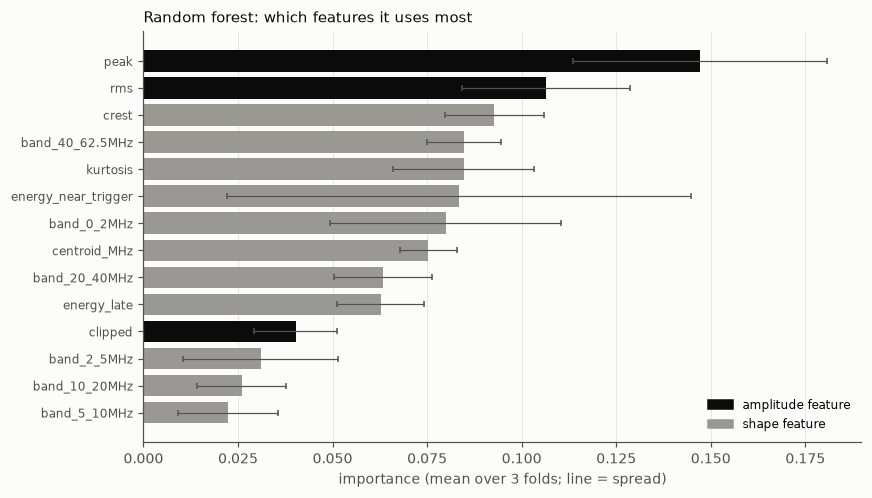

In [12]:
imp = []
for k in range(3):
    tr, _ = fold_split(files, k)
    rf = MODELS["Random forest"]().fit(F[ALL].values[tr], y[tr])
    imp.append(rf.feature_importances_)
imp = pd.DataFrame(imp, columns=ALL)
order = imp.mean().sort_values().index

fig, ax = plt.subplots(figsize=(8, 4.6))
colors = [INK if c in AMPLITUDE else "#9a9893" for c in order]
ax.barh(range(len(order)), imp[order].mean(), xerr=imp[order].std(), color=colors,
        error_kw=dict(ecolor=INK2, lw=0.8, capsize=2))
ax.set_yticks(range(len(order)), order, fontsize=8)
ax.set_xlabel("importance (mean over 3 folds; line = spread)"); ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=INK, label="amplitude feature"), Patch(color="#9a9893", label="shape feature")],
          loc="lower right", fontsize=8)
ax.set_title("Random forest: which features it uses most", loc="left")
plt.tight_layout(); plt.show()

**Explanation:** `peak` and `rms` (dark) are the two most-used features, which agrees with part 7. The top shape features are `crest`, `kurtosis` and the highest frequency band (40–62.5 MHz), all of which describe a short, sharp, high-frequency spike. That matches the EDA's picture of PD. The long error lines (e.g. `energy_near_trigger`) show how much the ranking changes between folds.

## 9. Save the results

The scores are written to `models/baseline/` in the data root, together with the settings that produced them. Later CNN notebooks can load this file and compare against it directly.

In [13]:
out = ensure_dirs()["models"] / "baseline"
out.mkdir(exist_ok=True)
table = pd.concat([
    results.drop(columns="macro_f1 fold mean ± sd").assign(features="all"),
    pd.DataFrame(shape_only).T.assign(features="shape"),
]).rename_axis("model").reset_index()
table.to_csv(out / "results.csv", index=False)
(out / "config.json").write_text(json.dumps({
    "split": "session folds from the database (ureca.dataset.folds)",
    "n_files": int(len(files)),
    "features": {"amplitude": AMPLITUDE, "shape": SHAPE},
    "random_forest": {"n_estimators": 300, "min_samples_leaf": 2, "class_weight": "balanced", "random_state": 0},
    "logistic_regression": {"transform": "log1p + standardise", "class_weight": "balanced"},
}, indent=2))
print("saved to", out)
table.round(3)

saved to C:\Users\Thyme\OneDrive - Nanyang Technological University\URECA_project_root\models\baseline


,model,macro_f1,balanced_acc,accuracy,recall_partial_discharge,recall_switching_noise,recall_transient_noise,recall_spark_lighter,features
0,Dummy,0.227,0.250,0.832,0.000,1.000,0.000,0.000,all
1,Logistic regression,0.533,0.745,0.533,0.923,0.468,0.714,0.875,all
2,Random forest,0.763,0.828,0.880,1.000,0.885,0.429,1.000,all
3,Logistic regression,0.233,0.654,0.174,0.846,0.036,0.857,0.875,shape
4,Random forest,0.563,0.725,0.635,1.000,0.597,0.429,0.875,shape


## 10. Summary: the target for the CNN

| | macro-F1 (session folds) |
|---|---|
| Dummy (always switching noise) | 0.23 |
| Logistic regression, 14 features | 0.53 |
| **Random forest, 14 features** | **0.76** ← target to beat |
| Random forest, shape features only | 0.56 ← target for a CNN on peak-normalised input |

What we learnt:
1. **PD is already caught well** (13 of 13 by the forest). The weak points are the noise classes: one switching-noise session (1 Sep 09:49) is mistaken for transient noise, and the very rare transient noise is missed 4 times out of 7.
2. **Splitting by session matters.** A random split would have reported ≈ 0.92 and hidden these problems.
3. **The baseline relies on amplitude.** Part of that is recorder settings, so a model that only uses amplitude may fail on data from another setup.
4. **Scores vary a lot between folds.** Differences smaller than about ±0.1 between models are not meaningful yet.

**Next (notebook 04):** a small 1-D CNN on the raw waveform, trained with the same folds and the `DataLoader` from notebook 02, compared against the numbers in this table. It is worth trying both volts input and peak-normalised input.